# Capítulo 5 · Actividad: ¿quién sobrevivió al Titanic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/01_actividad_titanic_arbol.ipynb)

Entrena un **árbol de decisión** que prediga si un pasajero sobrevivió (`survived`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [81]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Que scikit-learn devuelva DataFrames (con nombres de columna) en lugar de arrays de NumPy
set_config(transform_output="pandas")
sns.set_theme(style="whitegrid")

# Semilla para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [82]:
#Se analiza la información que se tiene
df.info()
#tenemos 15 columnas, de las cuales casi la mitad son puras str.
#tenemos 891 entradas

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [83]:
df.describe().round(3)
#observamos que tiene varios rangos las columnas numericac
#survived esta normalizado: sobrevivio = 1 , no_sobrevivio = 0
#Pclas: se devide en 3 clases: 1, 2 y 3
#Edad: El rango va de 0.420 años? a 80años
#n_hermanos: 0 a 8 hermanos
#n_hijos o padres: 0 a 6
#tarifa: 0 a 512 libras

,survived,pclass,age,sibsp,parch,fare
count,891.000,891.000,714.000,891.000,891.000,891.000
mean,0.384,2.309,29.699,0.523,0.382,32.204
std,0.487,0.836,14.526,1.103,0.806,49.693
min,0.000,1.000,0.420,0.000,0.000,0.000
25%,0.000,2.000,20.125,0.000,0.000,7.910
50%,0.000,3.000,28.000,0.000,0.000,14.454
75%,1.000,3.000,38.000,1.000,0.000,31.000
max,1.000,3.000,80.000,8.000,6.000,512.329


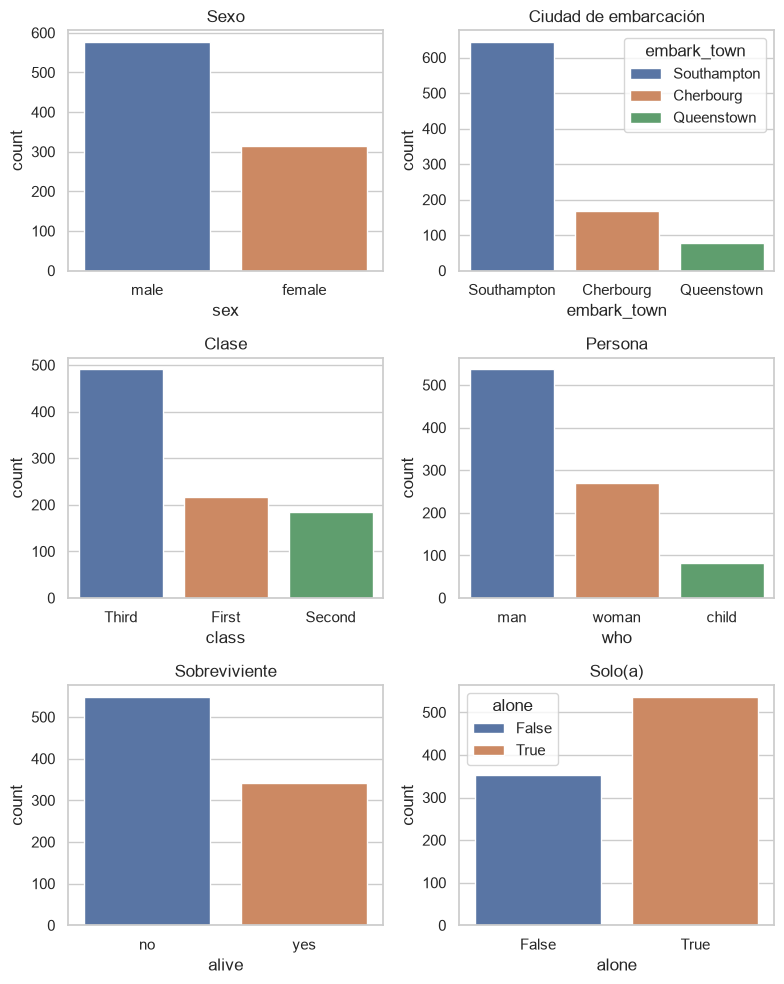

sex
male      577
female    314
Name: count, dtype: int64
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64
class
Third     491
First     216
Second    184
Name: count, dtype: int64
who
man      537
woman    271
child     83
Name: count, dtype: int64
alive
no     549
yes    342
Name: count, dtype: int64
alone
True     537
False    354
Name: count, dtype: int64


In [84]:
#las clases estan equilibradas?
fig, axes = plt.subplots(3,2,figsize=(8,10))
sns.countplot(data=df,x="sex",hue="sex",ax=axes[0,0])
sns.countplot(data=df,x="embark_town",hue="embark_town",ax=axes[0,1])
sns.countplot(data=df,x="class",hue="class",ax=axes[1,0])
sns.countplot(data=df,x="who",hue="who",ax=axes[1,1])
sns.countplot(data=df,x="alive",hue="alive",ax=axes[2,0])
sns.countplot(data=df,x="alone",hue="alone",ax=axes[2,1])
axes[0,0].set_title("Sexo")
axes[0,1].set_title("Ciudad de embarcación")
axes[1,0].set_title("Clase")
axes[1,1].set_title("Persona")
axes[2,0].set_title("Sobreviviente")
axes[2,1].set_title("Solo(a)")
plt.tight_layout() 
plt.show()

print(df["sex"].value_counts())
print(df["embark_town"].value_counts())
print(df["class"].value_counts())
print(df["who"].value_counts())
print(df["alive"].value_counts())
print(df["alone"].value_counts())


Se observa que no no hay equilibrio en ninguna categoria. Las categorias como **"Sexo"**, **"Solo(a)"** y la de **"Sobreviviente"**, tienden a una categoria a tener el doble de las otras. La unica categorio equilibrada esta en la grafica de **"clases"** entre la tercera y segunda clase.

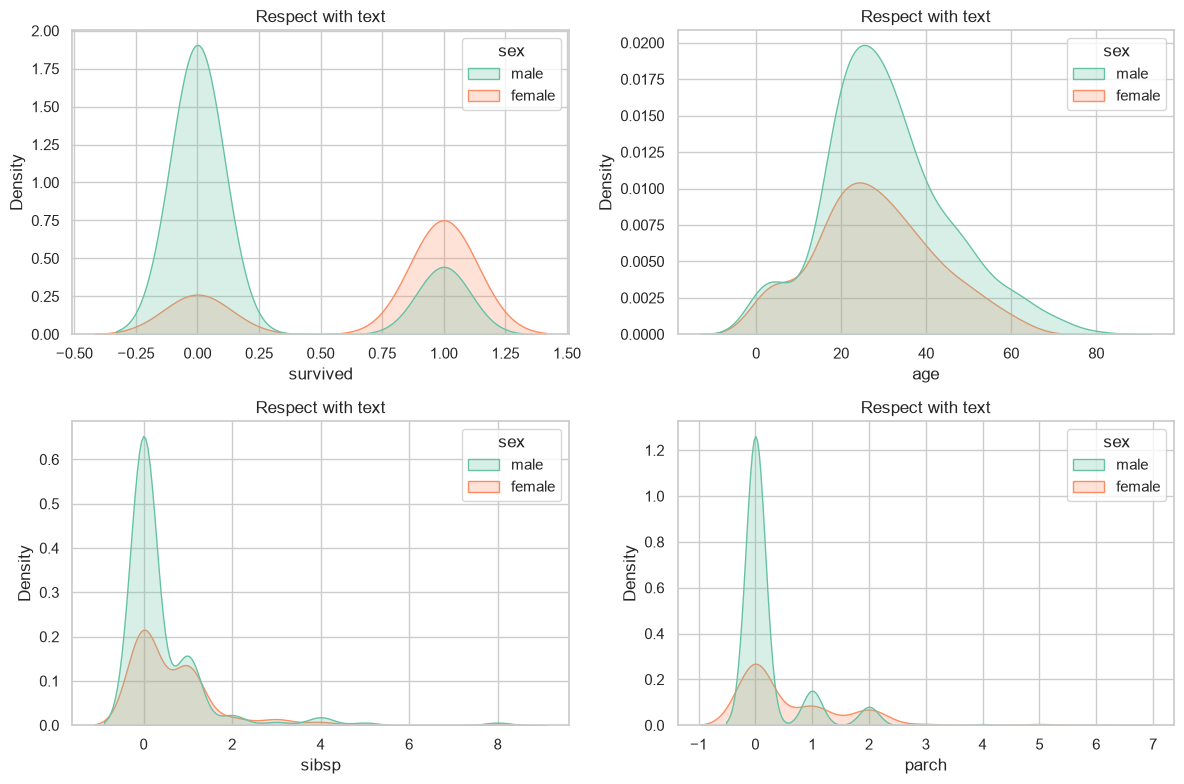

In [ ]:
variables = ["survived", "age","sibsp","parch","fare"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="sex", fill=True, palette="Set2", ax=ax)
    ax.set_title("Respect with Sex")
plt.tight_layout()
plt.show()

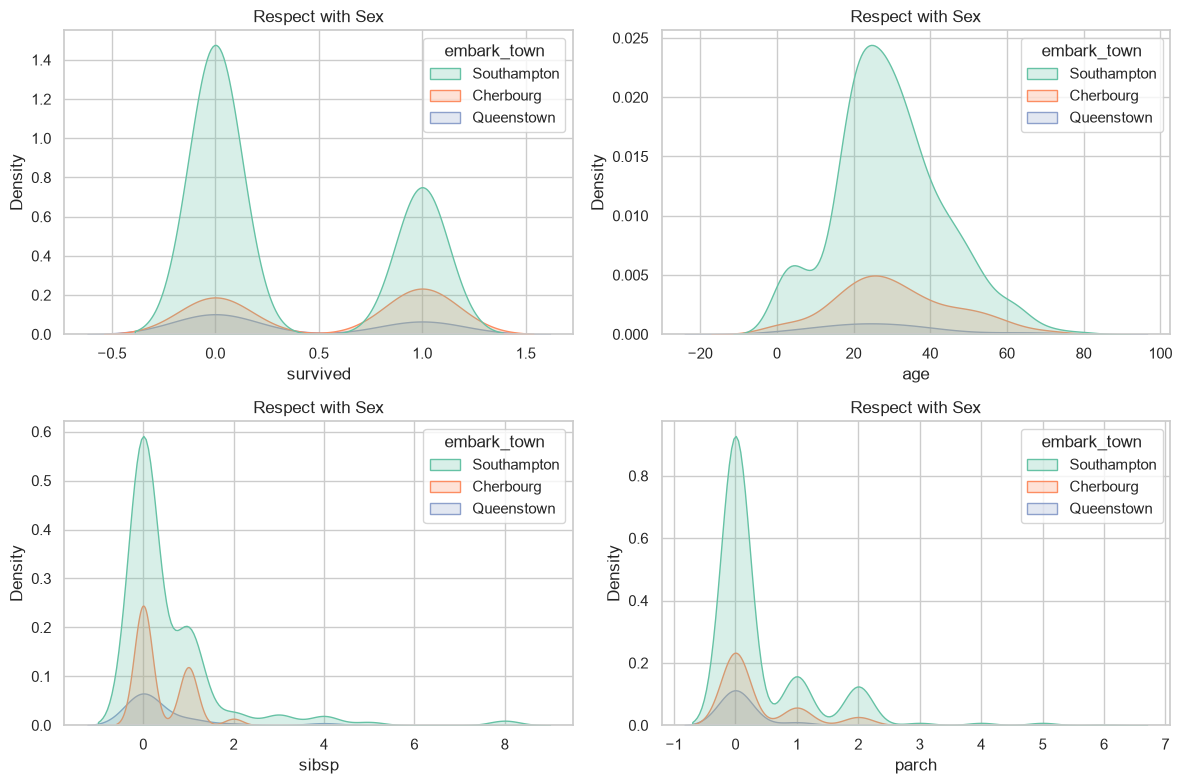

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="embark_town", fill=True, palette="Set2", ax=ax)
    ax.set_title("Respect with Sex")
plt.tight_layout()
plt.show()

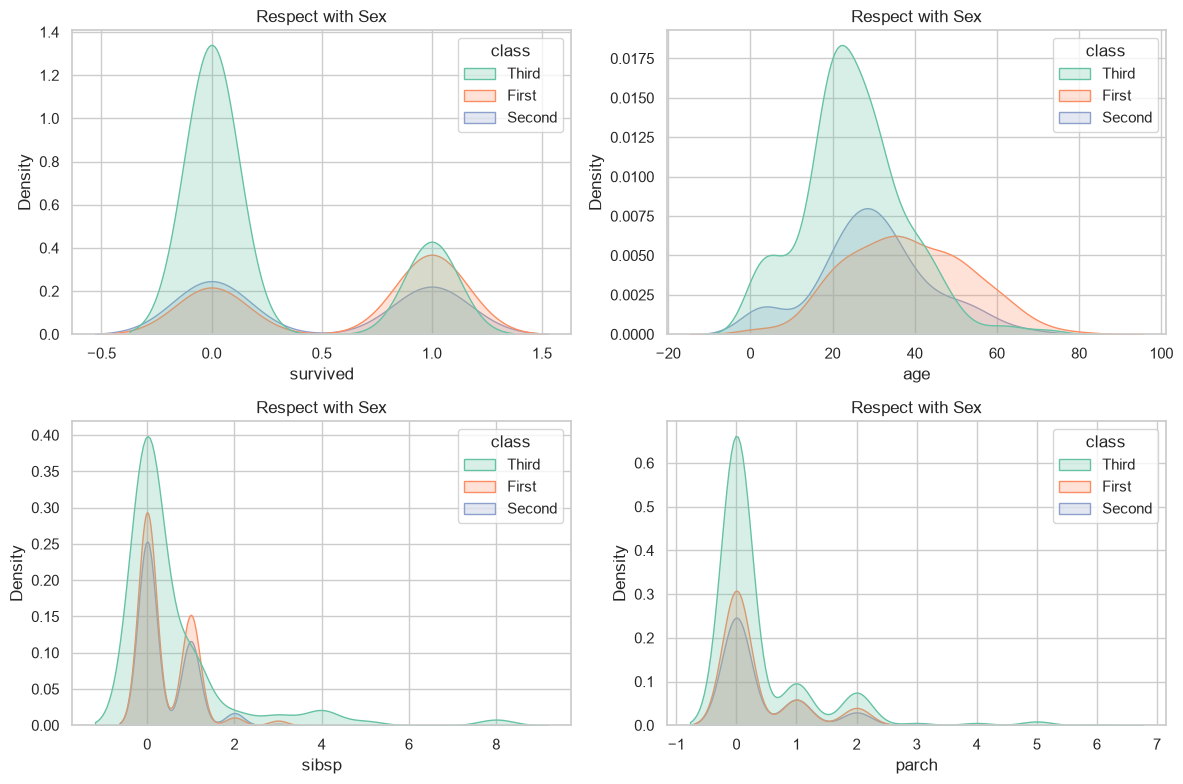

In [89]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="class", fill=True, palette="Set2", ax=ax)
    ax.set_title("Respect with Sex")
plt.tight_layout()
plt.show()

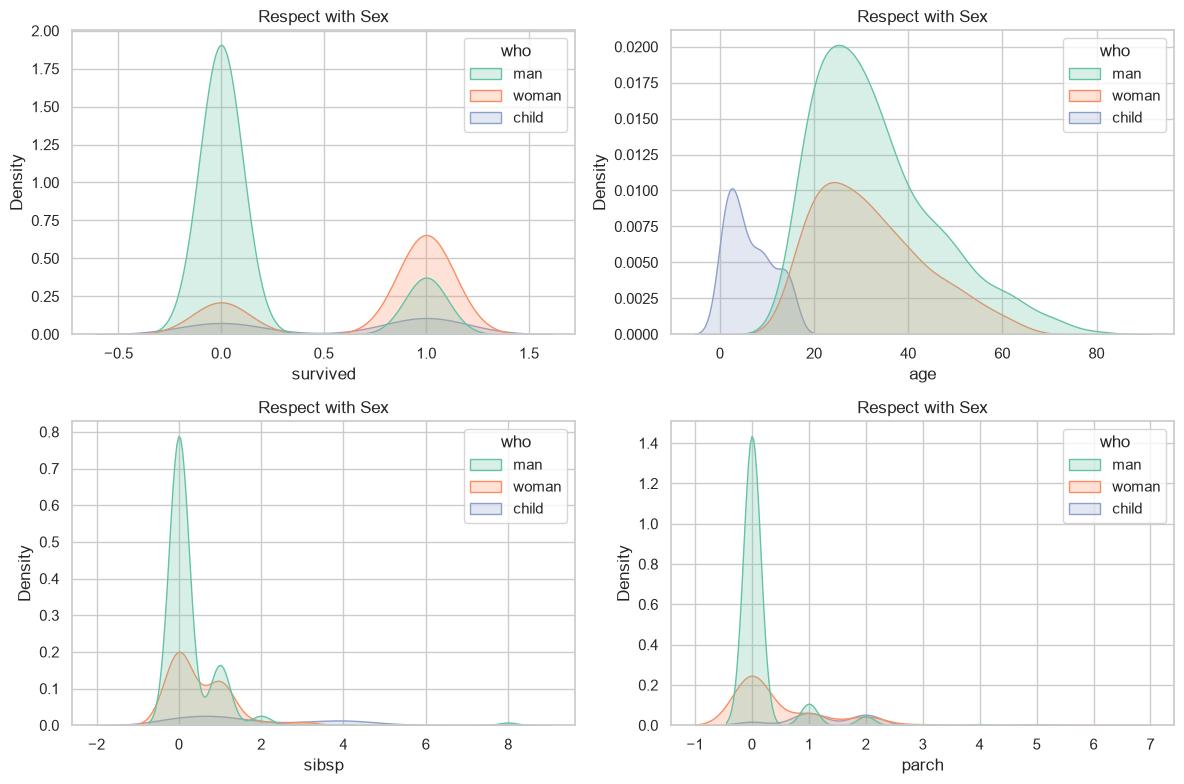

In [90]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="who", fill=True, palette="Set2", ax=ax)
    ax.set_title("Respect with Sex")
plt.tight_layout()
plt.show()

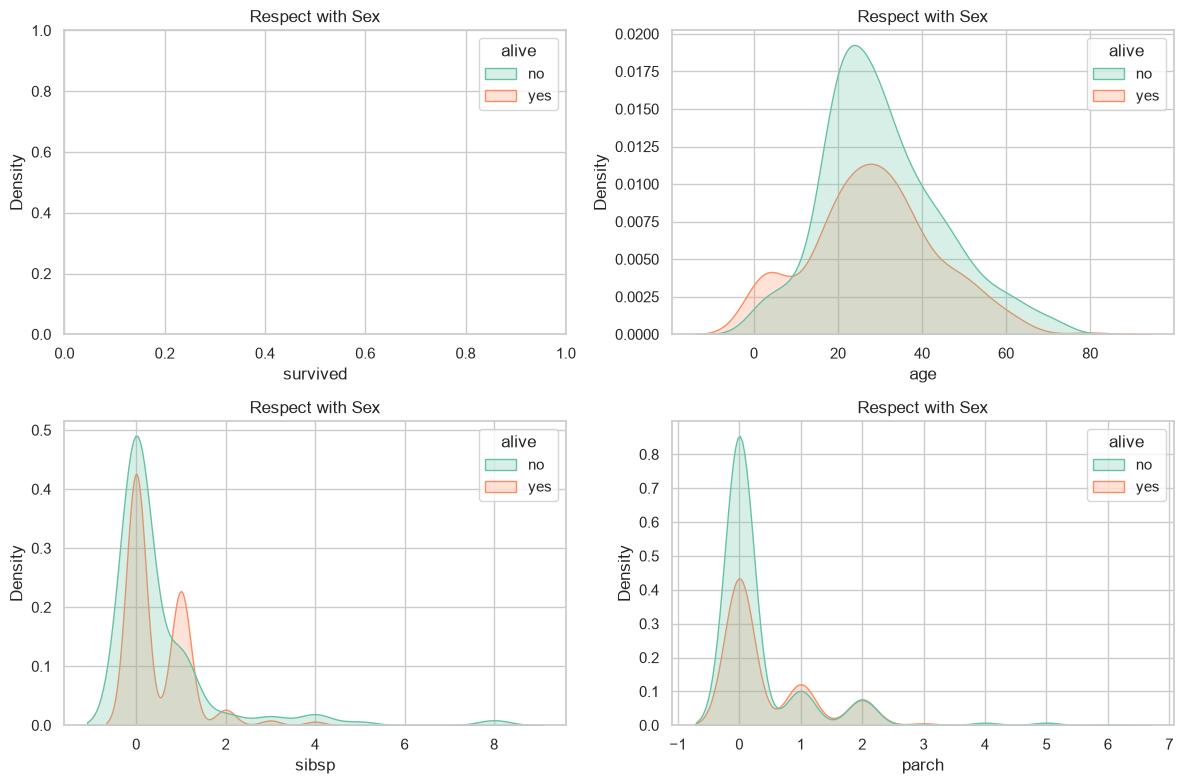

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="alive", fill=True, palette="Set2", ax=ax, warn_singular=False)
    ax.set_title("Respect with Sex")
plt.tight_layout()
plt.show()

C:\Users\flavs\AppData\Local\Temp\ipykernel_17208\3913880591.py:3: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df, x=variable, hue="alone", fill=True, palette="Set2", ax=ax)
C:\Users\flavs\AppData\Local\Temp\ipykernel_17208\3913880591.py:3: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df, x=variable, hue="alone", fill=True, palette="Set2", ax=ax)


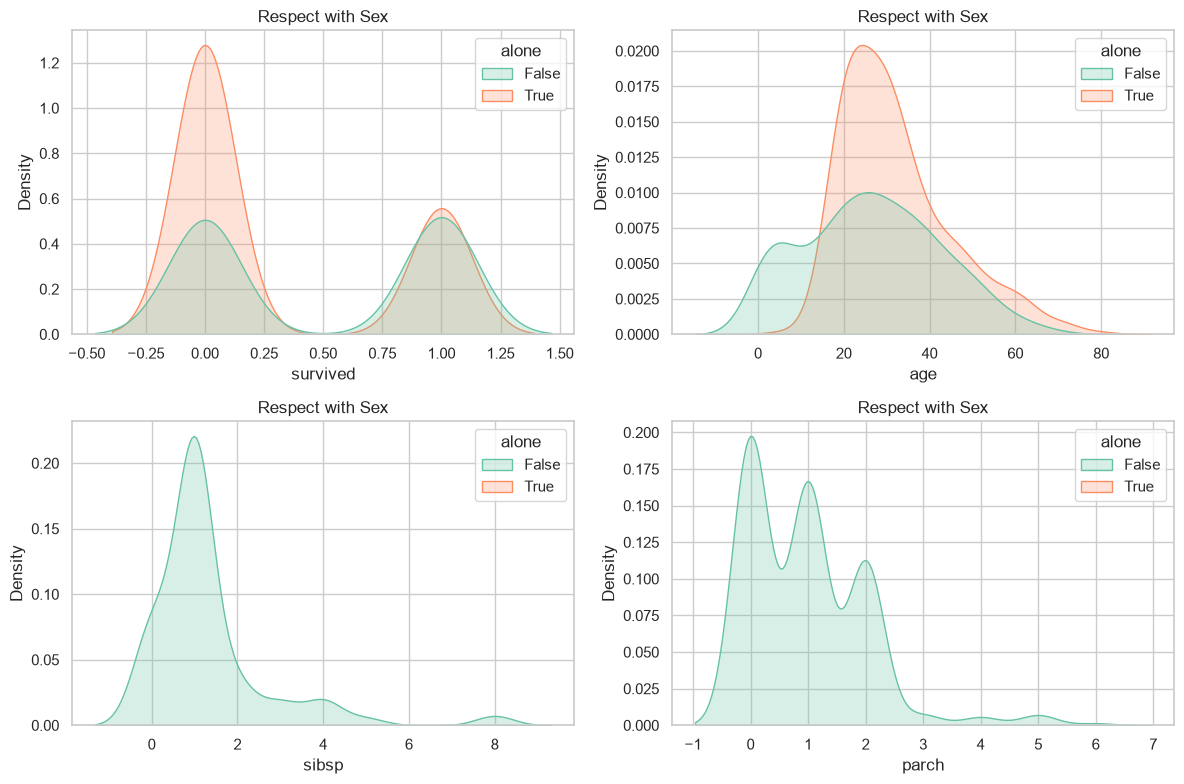

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for variable, ax in zip(variables, axes.flat):
    sns.kdeplot(data=df, x=variable, hue="alone", fill=True, palette="Set2", ax=ax)
    ax.set_title("Respect with Sex")
plt.tight_layout()
plt.show()